# Exploración de splits
Gráfico de imágenes por clase y partición.

train: 1920 imágenes ({'sano': 960, 'defecto': 960})
val: 240 imágenes ({'sano': 120, 'defecto': 120})
test: 240 imágenes ({'sano': 120, 'defecto': 120})
Fuente usada: /home/gnavarrete/navarrete_tesis/data/raw/USK-Coffee/train
Índice: /home/gnavarrete/navarrete_tesis/data/splits/index.csv


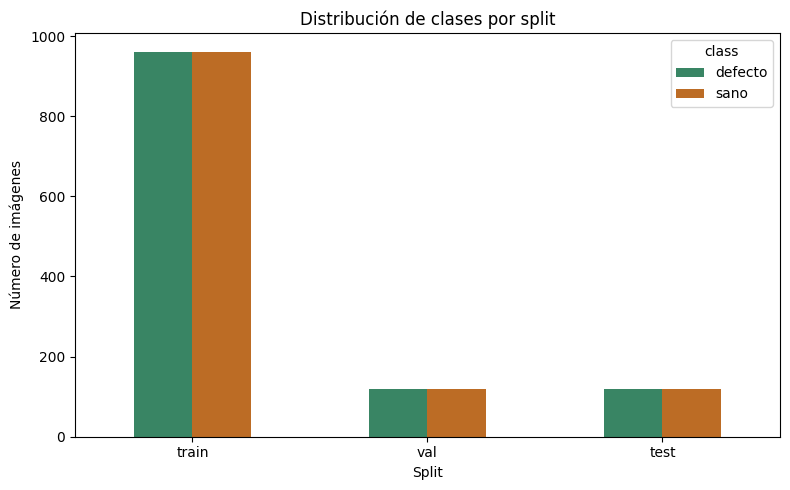

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd().resolve()
if not (ROOT / 'src').exists(): ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.data.build_splits import build_splits
index_path = ROOT / 'data/splits/index.csv'
build_splits()  # reconstruye splits desde las fuentes y actualiza index.csv
index = pd.read_csv(index_path)
counts = index.groupby(['split', 'class']).size().unstack(fill_value=0).reindex(['train', 'val', 'test'])
counts.plot(kind='bar', figsize=(8, 5), color=['#398564', '#bc6c25'])
plt.xlabel('Split'); plt.ylabel('Número de imágenes'); plt.title('Distribución de clases por split')
plt.xticks(rotation=0); plt.tight_layout()